# 20｜从手写数字出发：kNN、逻辑回归、SVM 与聚类

## 一张图片怎样变成一次判断？

面对一张从未见过的数字图片，我们可以找最相近的已知图片，查看邻居的标签；也可以学习一个把图片特征映射到类别的函数。本课让 kNN、逻辑回归和支持向量机（SVM）回答同一个问题，再用聚类观察没有标签时数据如何分组。

我们先用 scikit-learn 自带的 **digits** 数据：1,797 张 $8\times8$ 灰度图，每张有 64 个像素和 0–9 的标签。它不同于 **MNIST** 的 $28\times28$ 图像；后文给出可选的 MNIST 实验。两者都用于手写数字识别，但训练规模与像素分辨率不同，结果不能直接等同。

**本课路线：** 看图片与数组 → 训练/验证/测试划分 → 手算距离与投票 → 比较分类器 → 检查测试集 → 观察聚类。我们先在验证集上选择模型，再用一次留出测试估计选定模型的表现。

In [1]:
from support import ROOT, check, show, style

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, confusion_matrix, adjusted_rand_score
style()

## 1 从图像到特征矩阵

第 $i$ 张图片是一个 $8\times8$ 数组；将其按固定顺序拉直得到 $x_i\in\mathbb R^{64}$。整个数据集 $X$ 的形状为 `(样本数, 64)`，标签 $y$ 的形状为 `(样本数,)`。拉直保留了像素的位置顺序，但普通向量模型没有直接利用二维邻域结构。

images: (1797, 8, 8) features: (1797, 64) labels: (1797,)
pixel range: 0.0 16.0 class counts: [178 182 177 183 181 182 181 179 174 180]


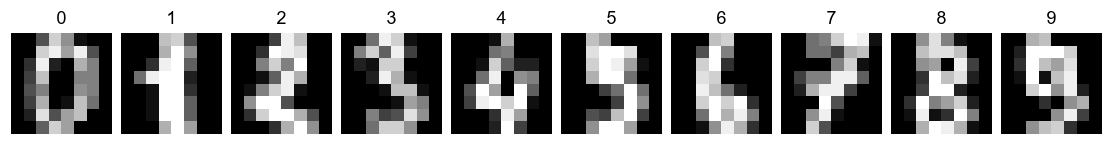

In [3]:
digits = load_digits()
X = digits.data.astype(float)
y = digits.target
print('images:', digits.images.shape, 'features:', X.shape, 'labels:', y.shape)
print('pixel range:', X.min(), X.max(), 'class counts:', np.bincount(y))
fig, axes = plt.subplots(1, 10, figsize=(10, 1.7), layout='constrained')
for ax, label in zip(axes, range(10)):
    index = np.flatnonzero(y == label)[0]
    ax.imshow(digits.images[index], cmap='gray', vmin=0, vmax=16)
    ax.set_title(str(label))
    ax.axis('off')
show(fig)

### 练习 cl01：确认一个样本的像素数

第 0 张 $8\times8$ 图片拉直后有多少个特征？将数字保存到 `ex_n_features`。

In [4]:
ex_n_features = None

In [5]:
# 填写上一格后，运行检查。
check('features per image', ex_n_features, 64)

待填写：features per image


<details>
<summary>提示</summary>

查看 `X.shape` 的第二个轴。

</details>

<details>
<summary>参考答案</summary>

```python
ex_n_features = X.shape[1]
```

</details>

## 2 先留出数据，再拟合预处理

先按类别分层抽取训练、验证和测试集，比例约为 60% / 20% / 20%。训练集用于拟合标准化统计量和模型，验证集用于模型选择，测试集留到选定后评价。

标准化对第 $j$ 个像素使用训练集的均值 $\mu_j$ 和标准差 $\sigma_j$：$z_j=(x_j-\mu_j)/\sigma_j$。当某个特征在训练集中没有变化时，`StandardScaler` 会处理零尺度，避免除零。`Pipeline` 把标准化和模型连在一起，以便 `fit` 只从训练集学习这些量。

In [6]:
X_train, X_rest, y_train, y_rest = train_test_split(
    X, y, test_size=.4, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(
    X_rest, y_rest, test_size=.5, stratify=y_rest, random_state=42)
print('train / validation / test:', len(y_train), len(y_val), len(y_test))
print('training labels:', np.bincount(y_train))

train / validation / test: 1078 359 360
training labels: [107 109 106 110 109 109 109 107 104 108]


## 3 kNN：让邻居投票

对于新图片 $x$ 和训练图片 $x_i$，欧氏距离为 $d(x,x_i)=\sqrt{\sum_j (x_j-x_{ij})^2}$。kNN 找出距离最小的 $k$ 个训练样本，采用其中出现次数最多的类别。$k$ 太小时，一个异常邻居可能改变判断；$k$ 变大时，判断会综合更大范围的邻居。

下面先在二维空间看这个动作。图中星号是待判断的点；这里每个点的颜色就是已知标签，圆圈标出最近的三个点。真正的数字图片有 64 个特征，无法直接画在这个二维图上。

distances: [1.803 1.118 1.803 1.118 1.5  ] nearest labels: [0 1 1]


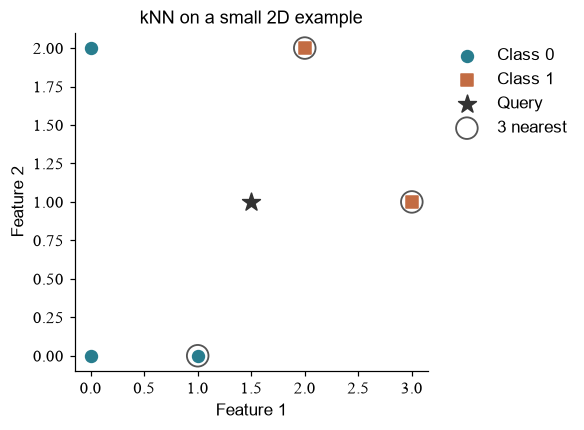

In [7]:
toy_points = np.array([[0., 0.], [1., 0.], [0., 2.], [2., 2.], [3., 1.]])
toy_labels = np.array([0, 0, 0, 1, 1])
query = np.array([1.5, 1.])
toy_distances = np.sqrt(((toy_points - query) ** 2).sum(axis=1))
nearest = np.argsort(toy_distances)[:3]
print('distances:', np.round(toy_distances, 3), 'nearest labels:', toy_labels[nearest])
fig, ax = plt.subplots(figsize=(5.2, 3.8), layout='constrained')
for label, color, marker in [(0, '#287d8e', 'o'), (1, '#c36c43', 's')]:
    points = toy_points[toy_labels == label]
    ax.scatter(points[:, 0], points[:, 1], color=color, marker=marker, s=60, label=f'Class {label}')
ax.scatter(*query, marker='*', color='#333333', s=150, label='Query')
ax.scatter(toy_points[nearest, 0], toy_points[nearest, 1], facecolors='none', edgecolors='#555555', s=200, linewidths=1.2, label='3 nearest')
ax.set(xlabel='Feature 1', ylabel='Feature 2', title='kNN on a small 2D example')
ax.legend(frameon=False, loc='upper left', bbox_to_anchor=(1.02, 1))
show(fig)

### 练习 cl02：手算距离

点 $(0,0)$ 与 $(3,4)$ 的欧氏距离是多少？存入 `ex_distance`。

In [8]:
ex_distance = None

In [9]:
# 填写上一格后，运行检查。
check('Euclidean distance', ex_distance, 5.)

待填写：Euclidean distance


<details>
<summary>提示</summary>

坐标差平方相加后开根号。

</details>

<details>
<summary>参考答案</summary>

```python
ex_distance = np.sqrt(3**2 + 4**2)
```

</details>

### 练习 cl03：多数投票

三个邻居的标签为 `[2, 2, 7]`。将多数类别存入 `ex_vote`。

In [10]:
ex_vote = None

In [11]:
# 填写上一格后，运行检查。
check('majority vote', ex_vote, 2)

待填写：majority vote


<details>
<summary>提示</summary>

统计各标签出现的次数。

</details>

<details>
<summary>参考答案</summary>

```python
ex_vote = 2
```

</details>

## 4 两种可学习的分类边界

**逻辑回归**（logistic regression）尽管名字带“回归”，常用于分类。二分类时，它先计算 $z=w^Tx+b$，再用 sigmoid $p=1/(1+e^{-z})$ 将分数映射到 0 到 1；改变阈值会改变分类决策。这里 scikit-learn 对 10 个类别使用多类别模型。

**支持向量机**（SVM）寻找类别之间的分隔。二分类中，对标签 $y_i\in\{-1,+1\}$，分数 $f(x)=w^Tx+b$ 的符号给出预测；$f(x)=0$ 是决策边界，而 $f(x)=\pm1$ 标记标准化后的两侧间隔。点到边界的垂直距离为 $|f(x)|/\|w\|$。

软间隔线性 SVM 用 hinge loss $\max(0,1-y_i f(x_i))$ 衡量间隔违反程度，并最小化 $\frac12\|w\|^2+C\sum_i\max(0,1-y_i f(x_i))$。其中 $C$ 控制对违例的惩罚。靠近间隔的样本会影响分隔面；这些支持向量在下图中圈出。此处的二维数据仅用于展示几何关系。

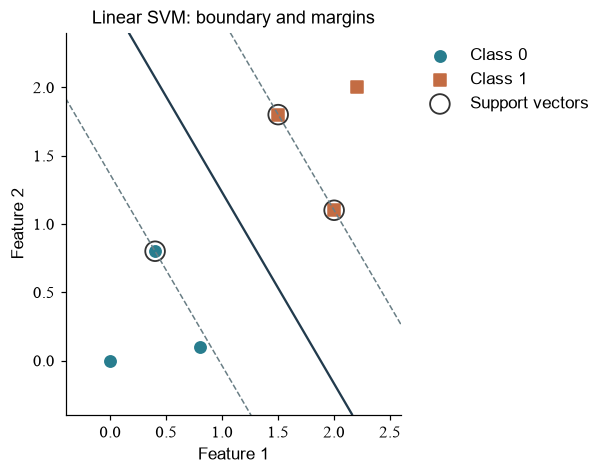

In [12]:
svm_points = np.array([[0., 0.], [.4, .8], [.8, .1], [1.5, 1.8], [2., 1.1], [2.2, 2.]])
svm_labels = np.array([0, 0, 0, 1, 1, 1])
toy_svm = SVC(kernel='linear', C=1.).fit(svm_points, svm_labels)
xx, yy = np.meshgrid(np.linspace(-.4, 2.6, 160), np.linspace(-.4, 2.4, 160))
scores = toy_svm.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
fig, ax = plt.subplots(figsize=(5.4, 4.2), layout='constrained')
for label, color, marker in [(0, '#287d8e', 'o'), (1, '#c36c43', 's')]:
    points = svm_points[svm_labels == label]
    ax.scatter(points[:, 0], points[:, 1], color=color, marker=marker, s=55, label=f'Class {label}')
ax.contour(xx, yy, scores, levels=[-1, 0, 1], colors=['#697e85', '#223b4d', '#697e85'],
           linestyles=['--', '-', '--'], linewidths=[1, 1.5, 1])
ax.scatter(toy_svm.support_vectors_[:, 0], toy_svm.support_vectors_[:, 1],
           facecolors='none', edgecolors='#333333', s=165, linewidths=1.2, label='Support vectors')
ax.set(xlabel='Feature 1', ylabel='Feature 2', title='Linear SVM: boundary and margins')
ax.legend(frameon=False, loc='upper left', bbox_to_anchor=(1.02, 1))
show(fig)

实线为 $f(x)=0$，虚线为 $f(x)=\pm1$。下面的数字分类实验使用线性核，十类别由二分类器组合处理。SVM 的分数与逻辑回归的概率不同。

比较模型时固定数据划分与准确率，保证它们回答同一个问题。标准化会影响 kNN 的距离，也会影响线性模型的优化与正则化，因此每个模型都在各自的 pipeline 中使用相同的训练集拟合流程。

### 练习 cl04：从分数到概率

二分类逻辑回归的分数 $z=0$，对应的 sigmoid 概率是多少？存入 `ex_probability`。

In [13]:
ex_probability = None

In [14]:
# 填写上一格后，运行检查。
check('sigmoid(0)', ex_probability, .5)

待填写：sigmoid(0)


<details>
<summary>提示</summary>

$e^0=1$。

</details>

<details>
<summary>参考答案</summary>

```python
ex_probability = 1/(1+np.exp(0))
```

</details>

In [15]:
models = {
    'Majority baseline': DummyClassifier(strategy='most_frequent'),
    'kNN (k=5)': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    'Logistic regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=42)),
    'Linear SVM': make_pipeline(StandardScaler(), SVC(kernel='linear', C=1.0)),
}
validation_scores = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    validation_scores[name] = accuracy_score(y_val, model.predict(X_val))
    print(f'{name:22s} validation accuracy = {validation_scores[name]:.3f}')
selected_name = max(validation_scores, key=validation_scores.get)
selected = models[selected_name]
print('selected on validation:', selected_name)

Majority baseline      validation accuracy = 0.100


kNN (k=5)              validation accuracy = 0.961
Logistic regression    validation accuracy = 0.967
Linear SVM             validation accuracy = 0.969
selected on validation: Linear SVM


## 5 锁定选择后，看测试与错例

准确率是预测正确的比例。它压缩了所有类别和错误，混淆矩阵则保留类别之间的误判：行是真实标签，列是预测标签。我们只在上面选好模型之后查看测试结果；多次尝试新方案时，应回到验证集完成选择。

selected test accuracy: 0.972


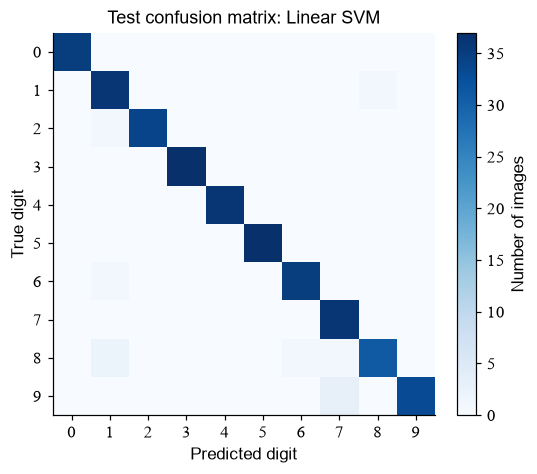

first error: true = 1 , predicted = 8


In [16]:
test_pred = selected.predict(X_test)
print('selected test accuracy:', round(accuracy_score(y_test, test_pred), 3))
cm = confusion_matrix(y_test, test_pred, labels=np.arange(10))
fig, ax = plt.subplots(figsize=(5, 4.2), layout='constrained')
im = ax.imshow(cm, cmap='Blues')
ax.set(xlabel='Predicted digit', ylabel='True digit', title=f'Test confusion matrix: {selected_name}',
       xticks=range(10), yticks=range(10))
fig.colorbar(im, ax=ax, label='Number of images')
show(fig)
errors = np.flatnonzero(test_pred != y_test)
if len(errors):
    print('first error: true =', y_test[errors[0]], ', predicted =', test_pred[errors[0]])

### 练习 cl05：读取混淆矩阵

若真实类别为 3、预测为 8，对应 `cm` 中哪一格？把实际计数放入 `ex_three_as_eight`。

In [17]:
ex_three_as_eight = None

In [18]:
# 填写上一格后，运行检查。
check('3 predicted as 8', ex_three_as_eight, cm[3, 8])

待填写：3 predicted as 8


<details>
<summary>提示</summary>

真实类别为行，预测类别为列。

</details>

<details>
<summary>参考答案</summary>

```python
ex_three_as_eight = cm[3, 8]
```

</details>

## 6 不看标签，能否把图片分组？

k-means 寻找 $k$ 个中心，交替执行“分给最近中心”和“重新计算各组均值”。它训练时不使用数字标签；聚类编号本身没有 0–9 的语义。下面只用训练图像拟合标准化与 10 个中心，再给验证图像分组；**调整兰德指数**（ARI）使用验证标签评估两种分组是否一致，1 表示完全一致，接近 0 表示接近随机分组。它不是分类准确率。

In [19]:
cluster_scaler = StandardScaler().fit(X_train)
cluster_model = KMeans(n_clusters=10, n_init=10, random_state=42)
cluster_model.fit(cluster_scaler.transform(X_train))
val_clusters = cluster_model.predict(cluster_scaler.transform(X_val))
print('validation adjusted Rand index:', round(adjusted_rand_score(y_val, val_clusters), 3))
print('first 12 cluster IDs:', val_clusters[:12])

validation adjusted Rand index: 0.415
first 12 cluster IDs: [1 1 6 8 9 9 3 9 4 1 4 1]


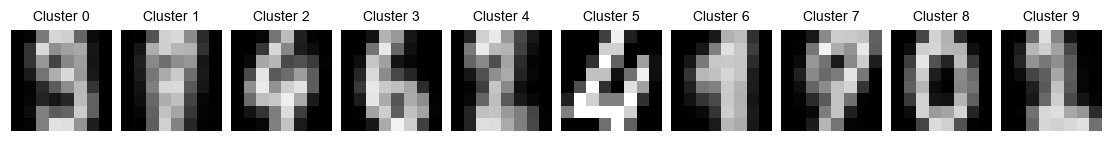

In [20]:
centers = cluster_scaler.inverse_transform(cluster_model.cluster_centers_).reshape(10, 8, 8)
fig, axes = plt.subplots(1, 10, figsize=(10, 1.7), layout='constrained')
for index, ax in enumerate(axes):
    ax.imshow(centers[index], cmap='gray', vmin=0, vmax=16)
    ax.set_title(f'Cluster {index}', fontsize=9)
    ax.axis('off')
show(fig)

中心图显示训练集上每个聚类的平均像素形状；编号只标识聚类，不能直接当作对应数字的标签。训练数据先被标准化，上图将中心逆变换回原始像素尺度以便阅读。

### 练习 cl06：计算二维中心

一组样本为 `(0, 2)`、`(2, 4)`。计算每个坐标的均值，保存为 `ex_centroid`。

In [21]:
ex_centroid = None

In [22]:
# 填写上一格后，运行检查。
check('centroid', ex_centroid, [1., 3.])

待填写：centroid


<details>
<summary>提示</summary>

分别对两个坐标求平均。

</details>

<details>
<summary>参考答案</summary>

```python
ex_centroid = np.array([1., 3.])
```

</details>

## 7 可选：将流程迁移到 MNIST

MNIST 有 70,000 张 $28\times28$ 图像。下面的代码可通过 OpenML **下载并缓存数据**，首次运行需要网络、磁盘空间和一定时间；纯 Python 解析可能较慢。默认开关为 `False`，不会下载。要运行本实验，将 `RUN_MNIST` 改为 `True`。先用分层抽样取 10,000 张，继续按训练/验证/测试划分；将像素除以 255 后可画图或输入模型。为了比较不同算法，保留同一份划分，并在训练集上拟合额外标准化。注意 kNN 的预测成本会随训练样本数增加。

In [23]:
# Set True to download and run the optional experiment.
RUN_MNIST = False
if RUN_MNIST:
    from sklearn.datasets import fetch_openml
    mnist = fetch_openml('mnist_784', version=1, as_frame=False, parser='liac-arff')
    mnist_X = mnist.data.astype(np.float32) / 255.0
    mnist_y = mnist.target.astype(int)
    mnist_small_X, _, mnist_small_y, _ = train_test_split(
        mnist_X, mnist_y, train_size=10000, stratify=mnist_y, random_state=42)
    mnist_train_X, mnist_rest_X, mnist_train_y, mnist_rest_y = train_test_split(
        mnist_small_X, mnist_small_y, test_size=.4, stratify=mnist_small_y, random_state=42)
    mnist_val_X, mnist_test_X, mnist_val_y, mnist_test_y = train_test_split(
        mnist_rest_X, mnist_rest_y, test_size=.5, stratify=mnist_rest_y, random_state=42)
    print('MNIST train / validation / test:', mnist_train_X.shape, mnist_val_X.shape, mnist_test_X.shape)
    fig, ax = plt.subplots(figsize=(2.8, 2.8), layout='constrained')
    ax.imshow(mnist_train_X[0].reshape(28, 28), cmap='gray', vmin=0, vmax=1)
    ax.set_title(f'MNIST label: {mnist_train_y[0]}'); ax.axis('off')
    show(fig)
else:
    print('Optional MNIST download skipped; set RUN_MNIST = True to enable it.')

Optional MNIST download skipped; set RUN_MNIST = True to enable it.


**继续实验：** 固定数据划分，只改变 $k$，画验证准确率曲线；用验证集选定 $k$ 后再报告测试结果。比较误判样本，思考像素距离为什么可能不能反映笔画的相似性。

阅读：[scikit-learn 最近邻](https://scikit-learn.org/stable/modules/neighbors.html)、[聚类](https://scikit-learn.org/stable/modules/clustering.html)和 [OpenML MNIST 示例](https://scikit-learn.org/stable/auto_examples/neural_networks/plot_mnist_filters.html)。找到各模型的训练数据和评价数据各自进入了哪个步骤。